In [1]:
# extrapolating to 3d

In [ ]:
import numpy as np
from astropy import units as u
import csv
from matplotlib.pyplot import cm

from matplotlib import pyplot as plt
from radial_interpolation import *
from radial import sm
from interp_and_iat_2d import *


hello again


In [ ]:
csm_dense_bkg = 8.705564515074679e-05 # g / cm2

499 499 0.005 arcsec True


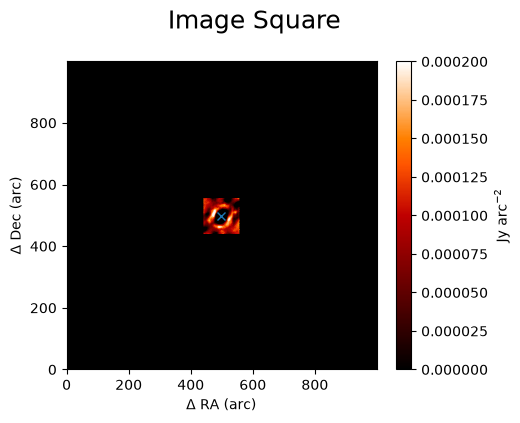

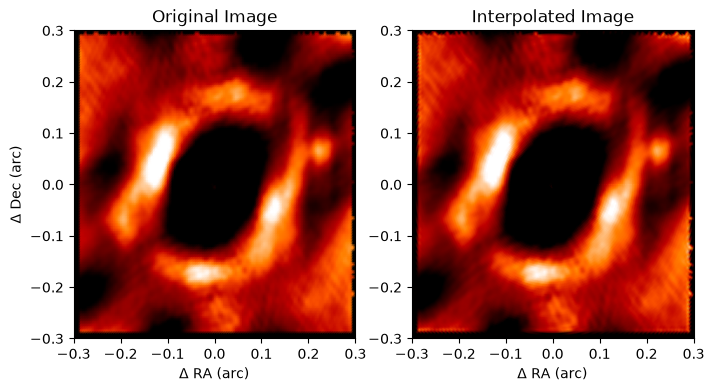

(1401, 500)


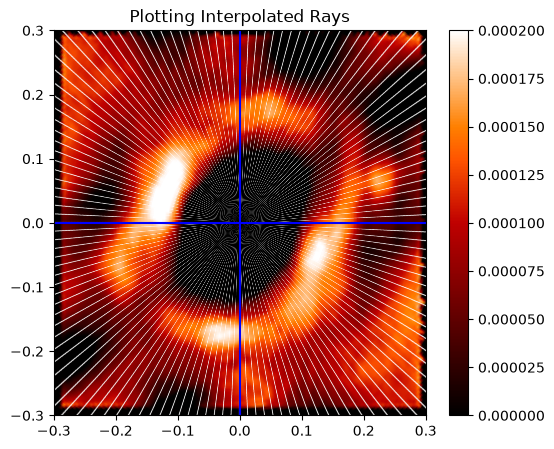

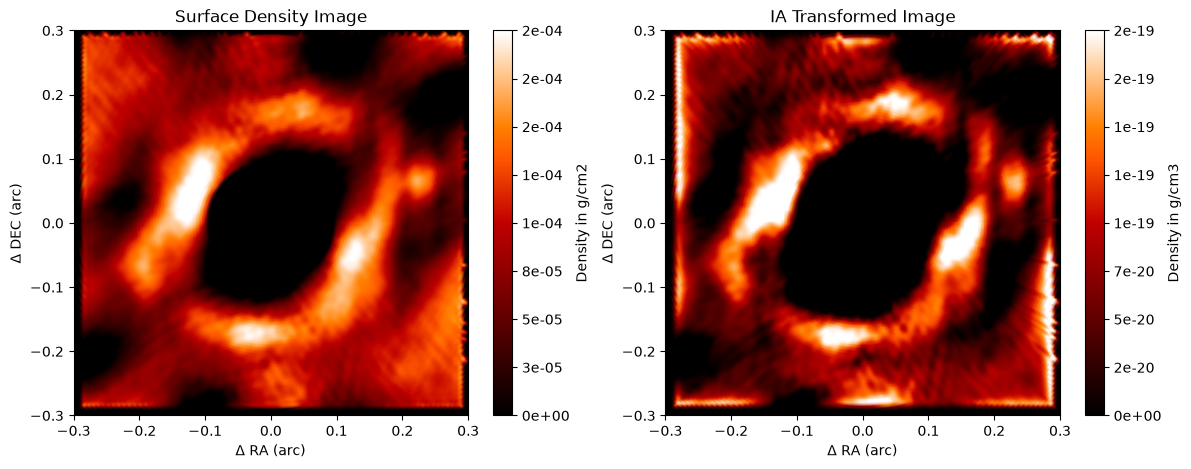

In [ ]:
x_grid_csm,y_grid_csm,interp_csm,radius_2d_arc_csm,radius_2d_pc_csm,csm_abel = read_in_density_file("saved_data/csm_2d_density.csv",center_x=499,center_y=499,vmax_gcm2=0.0002, vmax_gcm3=2e-19,
                                                                   nlines=1401,npoints=500,pix_size_arcsec = 0.005 * u.arcsec,return_grids=True,csm=True,bkg = csm_dense_bkg)

In [ ]:
csm_abel_zero = np.zeros_like(csm_abel)
for i in range(radius_2d_arc_csm.shape[0]):
    for j in range(radius_2d_arc_csm.shape[1]):
        if radius_2d_arc_csm[i,j]>0.1:
            csm_abel_zero[i,j]=csm_abel[i,j]
        else:
            csm_abel_zero[i,j] = 1e-99
csm_abel_zero[csm_abel_zero<=0] = 1e-99

In spherical coordinates

In [ ]:
phi = np.zeros_like(radius_2d_pc_csm.value)

for i in range(phi.shape[0]):
    for j in range(phi.shape[1]):
        phi[i,j] = (i/phi.shape[1]) *2

In [ ]:
x_grid_csm_pc = sm(168,x_grid_csm)
y_grid_csm_pc = sm(168,y_grid_csm)

In [ ]:
import pandas as pd

In [ ]:
r_list = []
phi_list = []
theta_list = []
rho_list = []

for i in range(radius_2d_pc_csm.shape[0]):
    for j in range(radius_2d_pc_csm.shape[1]):

        if phi[i,j]>=(42.3*np.pi/180) and phi[i,j]<(222.3*np.pi/180): # range of phis on one side of equator
            theta_side = np.linspace(0,np.pi,200) # one half of theta range
        elif phi[i,j]>=(222.3*np.pi/180) or phi[i,j]<(42.3*np.pi/180): # range of phis on other side of equator
            theta_side = np.linspace(np.pi,2*np.pi,200) # other half of theta range

        for th in theta_side: # make a duplicate point for each r along this side of line of sight
            r_list.append(radius_2d_pc_csm[i,j])
            phi_list.append(phi[i,j])
            rho_list.append(csm_abel_zero[i,j])
            theta_list.append(th)

        


In [ ]:
coords = pd.DataFrame({'r': r_list, 'phi': phi_list, 'theta': theta_list, 'rho': rho_list})

: 

In [ ]:
#convert to cartesian
coords['x'] = coords['r'] * np.sin(coords['theta']) * np.cos(coords['psi'])

In [ ]:
coords['y'] = coords['r'] * np.sin(coords['theta']) * np.sin(coords['psi'])


In [ ]:
coords['z'] = coords['r'] * np.cos(coords['theta'])

In [ ]:
coords.to_csv("saved_data/betelgeuse_csm_rho_and_coords.csv", index=False)

In [ ]:
# Source - https://stackoverflow.com/a/64015269
# Posted by arun, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-09, License - CC BY-SA 4.0

pd.set_option('display.max_rows', None)


In [ ]:
np.sum(np.array(theta_list)>0)

np.int64(0)

In [ ]:
z_grid_pc = np.sqrt(radius_2d_pc_csm.value**2-x_grid_csm_pc**2-y_grid_csm_pc**2)

/var/folders/bd/zqhz_9jx7gn5z5xnr8ynvz5h0000gn/T/ipykernel_58012/1386238355.py:1: RuntimeWarning: invalid value encountered in sqrt
  z_grid_pc = np.sqrt(radius_2d_pc_csm.value**2-x_grid_csm_pc**2-y_grid_csm_pc**2)


In [ ]:
#theta = np.arccos(z_grid_pc/radius_2d_pc_csm.value)

In [ ]:
#phi = np.arctan(y_grid_csm_pc/x_grid_csm_pc)

In [ ]:
radius_2d_pc_csm.shape

(1401, 500)

NameError: name 'theta' is not defined

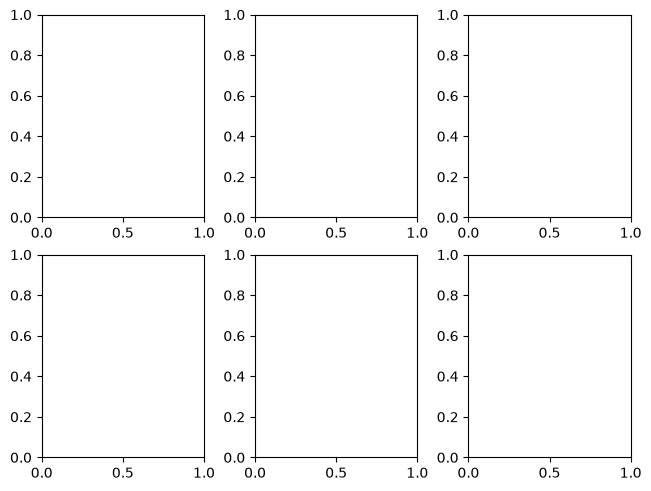

In [ ]:
fig, axs = plt.subplots(2,3, layout = 'constrained')

d = [[x_grid_csm_pc,y_grid_csm_pc,z_grid_pc],
     [radius_2d_pc_csm.value,theta,phi]]

t = [['x','y','z'],
     ['r','theta','phi']]
print(axs)
#for ax in zip(axs.flat):
for i in range(2):
    for j in range(3):
     im = axs[i,j].imshow(d[i][j])#,cmap='PiYG')
     fig.colorbar(im)
     
     axs[i,j].set_title(t[i][j])


/var/folders/bd/zqhz_9jx7gn5z5xnr8ynvz5h0000gn/T/ipykernel_10419/2403443486.py:2: RuntimeWarning: invalid value encountered in sqrt
  im = axs.imshow(np.sqrt((x_grid_csm_pc**2 + y_grid_csm_pc**2)**2-(x_grid_csm_pc**2 + y_grid_csm_pc**2)))#,cmap='PiYG')


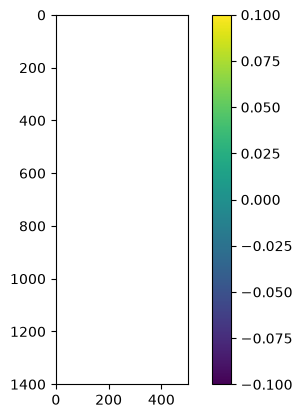

In [ ]:
fig,axs=plt.subplots(1,1)
im = axs.imshow(np.sqrt((x_grid_csm_pc**2 + y_grid_csm_pc**2)**2-(x_grid_csm_pc**2 + y_grid_csm_pc**2)))#,cmap='PiYG')
fig.colorbar(im)

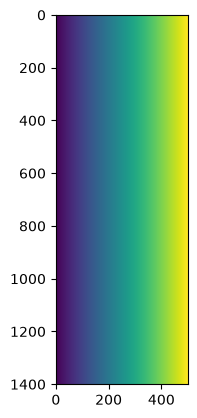

In [ ]:
plt.imshow(np.sqrt(x_grid_csm_pc**2 + y_grid_csm_pc**2))

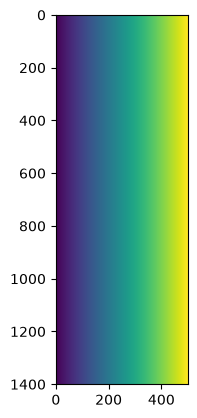

In [ ]:
plt.imshow(np.sqrt(x_grid_csm_pc**2 + y_grid_csm_pc**2 + z_grid_pc**2))

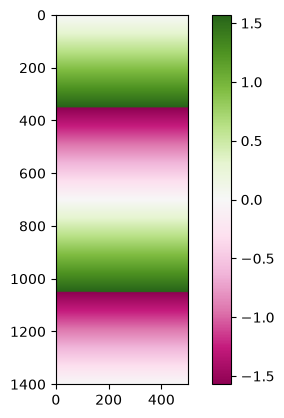

In [ ]:
plt.imshow(phi,cmap='PiYG')
plt.colorbar()